In [68]:
import numpy as np
import matplotlib.pyplot as plt

In [69]:
def solve_bvp(eps, p, q, r, a, b, alpha0, beta0, gamma0, alpha1, beta1, gamma1, N):
  """
  Solves the BVP eps y''+p(X)y'+q(x)y = r(x) using finite differences.
  """
  h = (b-a)/N
  x = np.linspace(a, b, N+1)
  A = np.zeros((N+1, N+1))
  B = np.zeros(N+1)
  # Interior Points
  for i in range(1, N):    # it will calculate from 1 till N-1
    xi = x[i]
    A[i, i-1] = eps - p(xi)*h/2     # Left Neighbor
    A[i, i] = q(xi)*h**2 - 2*eps    # Center
    A[i, i+1] = eps + p(xi)*h/2     # Right Neighbor
    B[i] = r(xi) * h**2
  # Boundary conditions
  A[0, 0] = alpha0*h - beta0    # Left
  A[0, 1] = beta0
  B[0] = gamma0 * h
  A[N, N-1] = -beta1    # Right
  A[N, N] = alpha1*h + beta1
  B[N] = gamma1 * h
  # Solve the system
  Y = np.linalg.solve(A, B)
  # print(A, B)
  return x, Y

In [70]:
# Example problem: y''+2xy'+2y = 5x, 0 <= x <= 0.5, with boundary conditions y(0) = 1, y(0.5) = 1.5
def p(x):
  return 2*x    # No first derivative term

In [71]:
def q(x):
  return 2    # y''-y = x

In [72]:
def r(x):
  return 5 * x

In [73]:
eps = 1
a,b = 0, 0.5
alpha0, beta0, gamma0 = 1, 0, 0    # y(0) = 0
alpha1, beta1, gamma1 = 1, 0, 1.5    # y(1) = 1
N = 20                             # Number of internal points

In [74]:
x, Y = solve_bvp(eps, p, q, r, a, b, alpha0, beta0, gamma0, alpha1, beta1, gamma1, N)

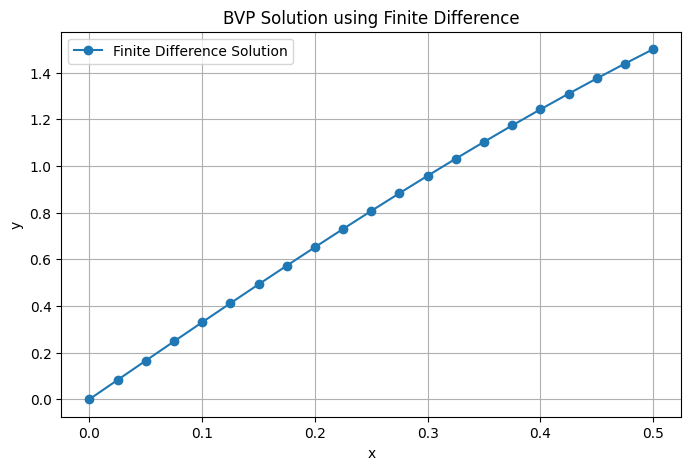

In [75]:
# Plot the results
plt.figure(figsize=(8, 5))
plt.plot(x, Y, label='Finite Difference Solution', marker='o')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.title('BVP Solution using Finite Difference')
plt.grid()
plt.show()

In [76]:
# Example 2: y''+sinxy'+xy = 4exp(x), 0 <= x <= 1, with y(0) = 0, y'(1) = 0
def p2(x):
  return np.sin(x)

In [77]:
def q2(x):
  return -x

In [78]:
def r2(x):
  return 4 * np.exp(x)

In [79]:
a2, b2 = 0, 1
alpha0_2, beta0_2, gamma0_2 = 1, 0, 0    # y(0) = 1
alpha1_2, beta1_2, gamma1_2 = 0, 1, 0    # y'(1) = 0
N2 = 40

In [80]:
x2, Y2 = solve_bvp(eps, p2, q2, r2, a2, b2, alpha0_2, beta0_2, gamma0_2, alpha1_2, beta1_2, gamma1_2, N2)

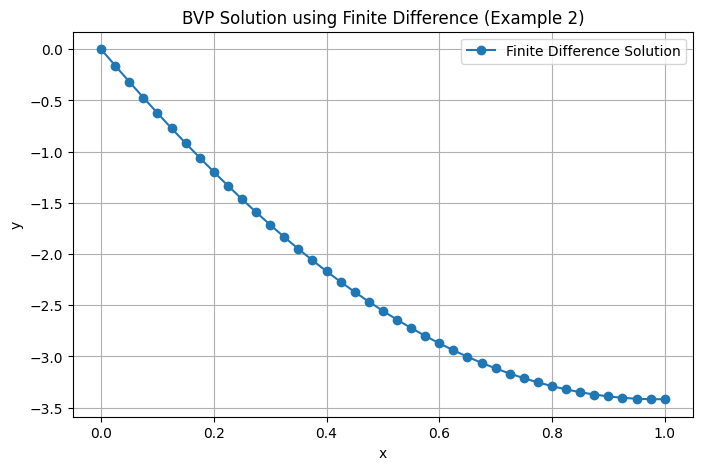

In [81]:
# Plot the results
plt.figure(figsize=(8, 5))
plt.plot(x2, Y2, label='Finite Difference Solution', marker='o')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.title('BVP Solution using Finite Difference (Example 2)')
plt.grid()
plt.show()